# SAR, SDM, SEM, dan SLX

ditulis: tim PSE Atha Bintang Wahyu M. | PSE UGM

--> Sampel 34 × 2017–2024. Estimasi FGLS.
--> Tahun 2025 di luar model: blok z-score belum disusun ulang, tenaga kerja 2025 menyalin 2024.
--> Dua W: queen kontiguitas darat, dan pulau.
--> Island W = rata-rata provinsi lain di pulau yang sama.
--> Seri pada gambar adalah `logtfp_it`.
--> Gambar: `01 Data/TFP/output/eda/`.


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams
from scipy.stats import chi2

def find_root():
    here = Path.cwd().resolve()
    for cand in [here, *here.parents]:
        if (cand / "2026bkpm.Rproj").exists():
            return cand
    return Path("/Users/athamawardi/Desktop/Research-Projects/RDSI_Kemeninves")

ROOT = find_root()
CODE = ROOT / "02 Code" / "TFP"
OUT = ROOT / "01 Data" / "TFP" / "output" / "eda"
OUT.mkdir(parents=True, exist_ok=True)
import types, sys
eda3_spatial_fgls = types.ModuleType('eda3_spatial_fgls')
exec(r'''"""EDA3 spatial FGLS engine — SAR / SDM / SEM / SLX, queen + island W.

Run from root or import from the notebook. Not FE2W: heteroskedastic IGLS
(xtgls panels(heteroskedastic)) on levels, intercept kept, no double demean.
"""
from __future__ import annotations

from pathlib import Path

import geopandas as gpd
import numpy as np
import pandas as pd
from numpy.linalg import slogdet
from scipy.optimize import minimize
from scipy.stats import chi2, norm

NAME2CODE = {
    "Aceh": 11, "SumateraUtara": 12, "SumateraBarat": 13, "Riau": 14,
    "Jambi": 15, "SumateraSelatan": 16, "Bengkulu": 17, "Lampung": 18,
    "BangkaBelitung": 19, "KepulauanRiau": 21, "JakartaRaya": 31,
    "JawaBarat": 32, "JawaTengah": 33, "Yogyakarta": 34, "JawaTimur": 35,
    "Banten": 36, "Bali": 51, "NusaTenggaraBarat": 52,
    "NusaTenggaraTimur": 53, "KalimantanBarat": 61, "KalimantanTengah": 62,
    "KalimantanSelatan": 63, "KalimantanTimur": 64, "KalimantanUtara": 65,
    "SulawesiUtara": 71, "SulawesiTengah": 72, "SulawesiSelatan": 73,
    "SulawesiTenggara": 74, "Gorontalo": 75, "SulawesiBarat": 76,
    "Maluku": 81, "MalukuUtara": 82, "PapuaBarat": 91, "Papua": 94,
}

HR = ["z_educ", "z_ln_campus", "z_ipm", "z_eq"]
INST = ["z_price", "z_rasio_pad", "z_serapan_belanja", "z_safe", "z_idi"]
CONN = ["z_jalan_mantap", "z_ln_airport", "z_ln_cargo"]
IND = ["z_ln_wage"]
ENV = ["z_iklh"]
RAW = HR + INST + CONN + IND + ENV

LAB = {
    "z_educ": "pendidikan",
    "z_ln_campus": "ln kampus",
    "z_ipm": "IPM",
    "z_eq": "−Gini",
    "z_price": "−deflator",
    "z_rasio_pad": "rasio PAD",
    "z_serapan_belanja": "serapan belanja",
    "z_safe": "−ln pidana",
    "z_idi": "IDI",
    "z_jalan_mantap": "jalan mantap",
    "z_ln_airport": "ln bandara",
    "z_ln_cargo": "ln kargo",
    "z_ln_wage": "ln upah agr.",
    "z_iklh": "IKLH",
    "idx_hr": "SDM (PC1)",
    "idx_inst": "institusi (PC1)",
    "idx_conn": "konektivitas (PC1)",
    "idx_ind": "industri (PC1)",
    "g_hr": "SDM (rata-z)",
    "g_inst": "institusi (rata-z)",
    "g_conn": "konektivitas (rata-z)",
    "g_ind": "industri (rata-z)",
    "const": "konstanta",
    "rho": "ρ (lag Y)",
    "lam": "λ (error)",
}


def row_std(W):
    s = W.sum(1, keepdims=True)
    s[s == 0] = 1
    return W / s


def apply_W(v, W, T):
    n = W.shape[0]
    out = np.empty_like(v, dtype=float)
    for t in range(T):
        sl = slice(t * n, (t + 1) * n)
        out[sl] = W @ v[sl]
    return out


def stack_WX(X, W, T):
    n = W.shape[0]
    out = np.empty_like(X, dtype=float)
    for t in range(T):
        sl = slice(t * n, (t + 1) * n)
        out[sl] = W @ X[sl]
    return out


def logdet_I_rhoW(rho, W):
    sign, ld = slogdet(np.eye(W.shape[0]) - rho * W)
    return float(ld) if sign > 0 else -1e12


def wls(y, X, inv):
    sw = np.sqrt(np.clip(inv, 1e-12, None))
    b, *_ = np.linalg.lstsq(X * sw[:, None], y * sw, rcond=None)
    return b


def pc1(Z, anchor_idx=0):
    """Correlation PCA via SVD on already z-scored columns. Orient by anchor."""
    Z = np.asarray(Z, float)
    if Z.ndim == 1 or Z.shape[1] == 1:
        z = Z.reshape(-1)
        z = (z - z.mean()) / z.std(ddof=1)
        return z, np.array([1.0])
    Zc = Z - Z.mean(0)
    _u, _s, vt = np.linalg.svd(Zc, full_matrices=False)
    loading = vt[0].copy()
    score = Zc @ loading
    if loading[anchor_idx] < 0:
        loading = -loading
        score = -score
    score = (score - score.mean()) / score.std(ddof=1)
    return score, loading


def zstd(x):
    x = np.asarray(x, float)
    return (x - x.mean()) / x.std(ddof=1)


def stars(z):
    if z != z:
        return ""
    a = abs(z)
    if a >= 2.576:
        return "***"
    if a >= 1.96:
        return "**"
    if a >= 1.645:
        return "*"
    return ""


def build_W(codes, pulau, gadm):
    g = gpd.read_file(gadm)[["NAME_1", "geometry"]]
    g["Code_Prov"] = g.NAME_1.map(NAME2CODE).astype(int)
    g = g.set_index("Code_Prov").loc[list(codes)].to_crs(3857)
    g["geometry"] = g.geometry.simplify(2000, preserve_topology=True)
    n = len(codes)
    xy = np.column_stack([g.centroid.x.values, g.centroid.y.values])
    dist = np.sqrt(((xy[:, None, :] - xy[None, :, :]) ** 2).sum(2))
    np.fill_diagonal(dist, np.inf)
    Wq = np.zeros((n, n))
    for i, ci in enumerate(codes):
        gi = g.loc[ci].geometry
        for j in range(i + 1, n):
            if gi.distance(g.loc[codes[j]].geometry) < 1000:
                Wq[i, j] = Wq[j, i] = 1
    isolates = [int(codes[i]) for i in range(n) if Wq[i].sum() == 0]
    knn = []
    for i in range(n):
        if Wq[i].sum() == 0:
            j = int(np.argmin(dist[i]))
            Wq[i, j] = Wq[j, i] = 1
            knn.append((int(codes[i]), int(codes[j])))
    Wi = np.zeros((n, n))
    for i, ci in enumerate(codes):
        for j, cj in enumerate(codes):
            if i != j and pulau[ci] == pulau[cj]:
                Wi[i, j] = 1
    meta = {"isolates_before_knn": isolates, "knn_links": knn,
            "queen_links": int(Wq.sum() / 2), "gdf": g}
    return row_std(Wq), row_std(Wi), Wq, Wi, meta


def _prune(X, names):
    """Drop zero-variance *covariates*; keep intercept even if std=0."""
    keep = []
    for i, nm in enumerate(names):
        if i == 0 and nm == "const":
            keep.append(i)
        elif np.std(X[:, i]) > 1e-10:
            keep.append(i)
    X, names = X[:, keep], [names[i] for i in keep]
    if X.shape[1] <= 1:
        return X, names
    q, r = np.linalg.qr(X)
    diag = np.abs(np.diag(r))
    thresh = 1e-8 * (diag.max() if diag.size else 1.0)
    keep = [i for i, d in enumerate(diag) if i == 0 or d > thresh]
    return X[:, keep], [names[i] for i in keep]


def _cluster_se(X, e, inv, n, T):
    """CR1 sandwich on WLS (weights inv), clustered by province."""
    nt, k = X.shape
    sw = np.sqrt(np.clip(inv, 1e-12, None))
    Xs = X * sw[:, None]
    es = e * sw
    xtx = np.linalg.pinv(Xs.T @ Xs)
    meat = np.zeros((k, k))
    for i in range(n):
        idx = [t * n + i for t in range(T)]
        s = Xs[idx].T @ es[idx]
        meat += np.outer(s, s)
    dfc = (n / (n - 1)) * ((nt - 1) / max(nt - k, 1))
    V = dfc * xtx @ meat @ xtx
    se = np.sqrt(np.maximum(np.diag(V), 0))
    return se, V


def _ll(e, inv, T, ld):
    """Gaussian ll after concentrating a global scale on top of inv=1/s2_i."""
    nt = len(e)
    phi = float(np.sum(inv * e ** 2) / nt)
    phi = max(phi, 1e-12)
    return float(
        -0.5 * nt * np.log(2 * np.pi * phi)
        + 0.5 * np.sum(np.log(np.clip(inv, 1e-12, None)))
        - 0.5 * nt
        + T * ld
    )


def _min1d(fn, lo=-0.85, hi=0.85, ngrid=29):
    grid = np.linspace(lo, hi, ngrid)
    vals = np.array([fn(r) for r in grid])
    r0 = float(grid[int(np.nanargmin(vals))])
    res = minimize(lambda z: fn(float(np.asarray(z).ravel()[0])),
                   [r0], method="L-BFGS-B", bounds=[(lo, hi)])
    rho = float(res.x[0])
    return rho, float(res.fun), bool(res.success)


def _fd_se(fn, x, lo, hi, eps=1e-4):
    if not (lo + 3 * eps < x < hi - 3 * eps):
        return np.nan
    f0, fp, fm = fn(x), fn(x + eps), fn(x - eps)
    hess = (fp - 2 * f0 + fm) / (eps ** 2)
    return float(np.sqrt(1 / hess)) if hess > 0 else np.nan


def fit_fgls(y, X, names, W, T, kind="FGLS", niter=8, lo=-0.85, hi=0.85):
    """kind in {FGLS, SLX, SAR, SDM, SEM}. X includes intercept as col 0."""
    n = W.shape[0] if W is not None else None
    names = list(names)
    Xuse = np.asarray(X, float)
    y = np.asarray(y, float)

    if kind in ("SLX", "SDM"):
        wx = stack_WX(Xuse[:, 1:], W, T)
        wnames = [f"W_{nm}" for nm in names[1:]]
        Xuse = np.column_stack([Xuse, wx])
        names = names + wnames

    Xuse, names = _prune(Xuse, names)
    nt, k = Xuse.shape
    inv = np.ones(nt)
    spatial = kind in ("SAR", "SDM", "SEM")
    rho = 0.0
    hit_bound = False

    def nll_rho(r, inv_):
        r = float(r)
        if not (lo < r < hi):
            return 1e12
        ld = logdet_I_rhoW(r, W)
        if ld < -1e10:
            return 1e12
        nt = len(y)
        if kind == "SEM":
            Ay = y - r * apply_W(y, W, T)
            AX = Xuse - r * stack_WX(Xuse, W, T)
            b = wls(Ay, AX, inv_)
            e = Ay - AX @ b
        else:
            Ay = y - r * apply_W(y, W, T)
            b = wls(Ay, Xuse, inv_)
            e = Ay - Xuse @ b
        sse = float(np.sum(inv_ * e ** 2))
        if sse <= 1e-12:
            return 1e12
        # concentrate global scale so Jacobian and SSE share a log-scale
        return 0.5 * nt * np.log(sse) - T * ld

    for it in range(niter):
        if spatial:
            rho, _f, _ok = _min1d(lambda r: nll_rho(r, inv), lo, hi)
        else:
            rho = 0.0
        if kind == "SEM":
            Ay = y - rho * apply_W(y, W, T)
            AX = Xuse - rho * stack_WX(Xuse, W, T)
            b = wls(Ay, AX, inv)
            e = Ay - AX @ b
            Xse = AX
        elif kind in ("SAR", "SDM"):
            Ay = y - rho * apply_W(y, W, T)
            b = wls(Ay, Xuse, inv)
            e = Ay - Xuse @ b
            Xse = Xuse
        else:
            b = wls(y, Xuse, inv)
            e = y - Xuse @ b
            Xse = Xuse
            Ay = y
        if it < niter - 1:
            s2 = e.reshape(T, n if n else Xuse.shape[0] // T).var(axis=0, ddof=1)
            s2 = np.maximum(s2, 1e-8)
            inv = np.tile(1.0 / s2, T)
    s2 = e.reshape(T, n if n else Xuse.shape[0] // T).var(axis=0, ddof=1)
    s2 = np.maximum(s2, 1e-8)

    hit_bound = bool(spatial and (rho <= lo + 1e-3 or rho >= hi - 1e-3))
    ld = logdet_I_rhoW(rho, W) if spatial else 0.0
    ll = _ll(e, inv, T, ld)
    se_b, _V = _cluster_se(Xse, e, inv, n if n else 34, T)
    se_rho = _fd_se(lambda r: nll_rho(r, inv), rho, lo, hi) if spatial else np.nan
    z_rho = rho / se_rho if se_rho == se_rho and se_rho and se_rho > 0 else np.nan
    aic = -2 * ll + 2 * (k + (1 if spatial else 0))
    return {
        "kind": kind, "rho": rho, "se_rho": se_rho, "z_rho": z_rho,
        "ll": ll, "aic": aic, "k": k, "N": nt, "names": names,
        "beta": b, "se_b": se_b, "e": e, "inv": inv, "X": Xuse,
        "hit_bound": bool(hit_bound), "s2": s2,
    }


def effects(W, rho, beta_k, theta_k=0.0):
    n = W.shape[0]
    S = np.linalg.inv(np.eye(n) - rho * W) @ (np.eye(n) * beta_k + W * theta_k)
    total = float(S.sum(axis=1).mean())
    direct = float(np.diag(S).mean())
    return {"direct": direct, "indirect": total - direct, "total": total}


def moran(z, W):
    z = np.asarray(z, float) - np.mean(z)
    den = z @ z
    return float((z @ (W @ z)) / den) if den > 0 else np.nan


def load_panel(root: Path):
    tfp = pd.read_excel(root / "01 Data/TFP/output/konstruksi/TFP Provinsi 2017-2024.xlsx")
    det = pd.read_excel(root / "01 Data/TFP/output/determinan/Determinan TFP Provinsi 2017-2024.xlsx")
    peta = pd.read_csv(root / "01 Data/BKPM/processed/Dataset Provinsi(prov_name).csv")
    peta = peta.dropna(subset=["Code_Prov", "Pulau"]).drop_duplicates("Code_Prov")
    peta["Code_Prov"] = peta.Code_Prov.astype(int)
    d = tfp.merge(peta[["Code_Prov", "Pulau"]], on="Code_Prov")
    extra = [c for c in det.columns if c not in ("Code_Prov", "Year", "Pre_Prov", "logtfp_it", "logtfp_it_crs")]
    d = d.merge(det[["Code_Prov", "Year"] + extra], on=["Code_Prov", "Year"], how="left")
    d = d.sort_values(["Year", "Code_Prov"]).reset_index(drop=True)
    assert d[RAW].notna().all().all()
    return d
''', eda3_spatial_fgls.__dict__)
sys.modules['eda3_spatial_fgls'] = eda3_spatial_fgls

from eda3_spatial_fgls import (
    HR, INST, CONN, IND, RAW, LAB, NAME2CODE,
    pc1, zstd, stars, build_W, fit_fgls, effects, moran, load_panel, apply_W,
)

NAVY, CYAN, RED, TEAL, CREAM, PINK, GRAY, KERTAS = (
    "#0E2440", "#5DD0E6", "#D9042B", "#46A694", "#F2E6CE", "#F2509C", "#797F8C", "#ffffff",
)
PULAU_COLOR = {
    "Sumatera": CREAM, "Jawa": PINK, "Bali-Nusra": RED,
    "Kalimantan": "#062E4C", "Sulawesi": "#30726A", "Maluku-Papua": TEAL,
}
W_COLOR = {"queen": CYAN, "island": RED, "none": GRAY}
X_COLOR = {"pca": NAVY, "grup": TEAL, "raw": PINK}
KIND_HATCH = {"FGLS": "", "SLX": "//", "SAR": "", "SDM": "..", "SEM": "xx"}

rcParams.update({
    "figure.facecolor": KERTAS, "axes.facecolor": KERTAS, "axes.edgecolor": GRAY,
    "axes.grid": True, "grid.color": "#E6E6E6", "grid.linewidth": 0.6,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "medium",
})

def save(fig, name):
    p = OUT / name
    fig.savefig(p, dpi=140, bbox_inches="tight", facecolor=KERTAS)
    print("wrote", p.relative_to(ROOT))
    return p


In [2]:
d = load_panel(ROOT)
codes = sorted(d.Code_Prov.unique())
years = sorted(d.Year.unique())
n, T = len(codes), len(years)
assert len(d) == n * T == 272
pulau = dict(zip(
    d.drop_duplicates("Code_Prov").Code_Prov,
    d.drop_duplicates("Code_Prov").Pulau,
))
GADM = ROOT / "02 Code" / "TFP" / "docs" / "06 Review" / "assets" / "gadm41_IDN_1.json"
Wq, Wi, Wq_raw, Wi_raw, wmeta = build_W(codes, pulau, GADM)
Wmap = {"queen": Wq, "island": Wi}

print("N =", n, "T =", T, "queen taut", wmeta["queen_links"],
      "isolat+knn", wmeta["isolates_before_knn"], wmeta["knn_links"])

# --- tiga blok X ----------------------------------------------------------
L = {}
d["idx_hr"], L["hr"] = pc1(d[HR].to_numpy(), 2)       # jangkar IPM
d["idx_inst"], L["inst"] = pc1(d[INST].to_numpy(), 1)  # jangkar rasio PAD
d["idx_conn"], L["conn"] = pc1(d[CONN].to_numpy(), 0)  # jangkar jalan mantap
d["idx_ind"], L["ind"] = pc1(d[IND].to_numpy(), 0)     # 1 variabel = z upah
d["g_hr"] = zstd(d[HR].mean(axis=1))
d["g_inst"] = zstd(d[INST].mean(axis=1))
d["g_conn"] = zstd(d[CONN].mean(axis=1))
d["g_ind"] = zstd(d[IND].mean(axis=1))

BLOCKS = {
    "pca":  ["idx_hr", "idx_inst", "idx_conn", "idx_ind", "z_iklh"],
    "grup": ["g_hr", "g_inst", "g_conn", "g_ind", "z_iklh"],
    "raw":  list(RAW),
}
PILLARS = {
    "pca":  ["idx_hr", "idx_inst", "idx_conn", "idx_ind"],
    "grup": ["g_hr", "g_inst", "g_conn", "g_ind"],
}
y = d["logtfp_it"].to_numpy()
print("corr PC1 vs rata-z  SDM", f"{np.corrcoef(d.idx_hr, d.g_hr)[0,1]:.2f}",
      " inst", f"{np.corrcoef(d.idx_inst, d.g_inst)[0,1]:.2f}",
      " conn", f"{np.corrcoef(d.idx_conn, d.g_conn)[0,1]:.2f}")


KeyError: "['z_educ', 'z_ln_campus', 'z_ipm', 'z_eq', 'z_rasio_pad', 'z_serapan_belanja', 'z_safe', 'z_idi', 'z_jalan_mantap', 'z_ln_airport', 'z_ln_cargo', 'z_ln_wage', 'z_iklh'] not in index"

## PC1 dan rata-z

--> PCA pada penyusun z di panel kerja.
--> Angka pilar yang dipakai = rata-z.


wrote 01 Data/TFP/output/eda/eda3_pca_loadings.png


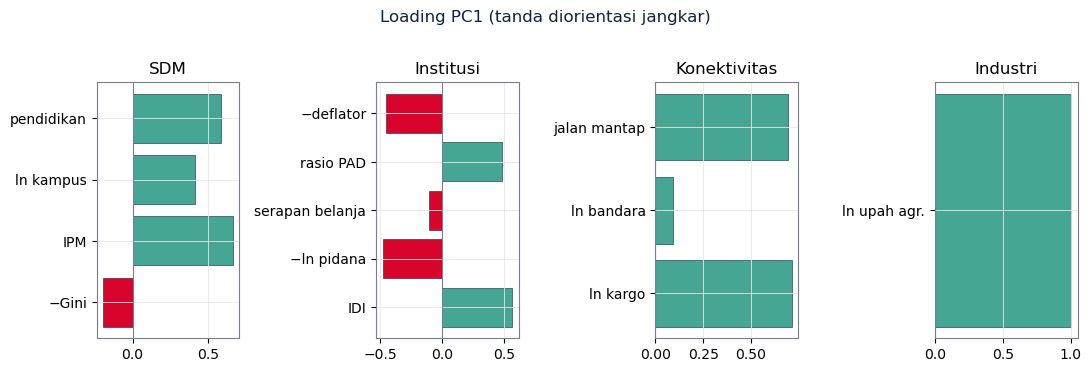

,pilar,var,label,loading
0,hr,z_educ,pendidikan,0.588241
1,hr,z_ln_campus,ln kampus,0.413179
2,hr,z_ipm,IPM,0.666963
3,hr,z_eq,−Gini,-0.195999
4,inst,z_price,−deflator,-0.450551
5,inst,z_rasio_pad,rasio PAD,0.483227
6,inst,z_serapan_belanja,serapan belanja,-0.100460
7,inst,z_safe,−ln pidana,-0.479234
8,inst,z_idi,IDI,0.568981
9,conn,z_jalan_mantap,jalan mantap,0.695319


In [ ]:
load_rows = []
for pilar, vars_ in [("hr", HR), ("inst", INST), ("conn", CONN), ("ind", IND)]:
    for v, ld in zip(vars_, np.atleast_1d(L[pilar])):
        load_rows.append({"pilar": pilar, "var": v, "label": LAB[v], "loading": float(ld)})
loadings = pd.DataFrame(load_rows)
loadings.to_csv(OUT / "eda3_pca_loadings.csv", index=False)

fig, axes = plt.subplots(1, 4, figsize=(11, 3.6), sharey=False)
for ax, pilar, title in zip(
    axes, ["hr", "inst", "conn", "ind"],
    ["SDM", "Institusi", "Konektivitas", "Industri"],
):
    sub = loadings[loadings.pilar == pilar]
    colors = [TEAL if v >= 0 else RED for v in sub.loading]
    ax.barh(sub.label, sub.loading, color=colors, edgecolor=NAVY, linewidth=0.4)
    ax.axvline(0, color=GRAY, lw=0.8)
    ax.set_title(title)
    ax.invert_yaxis()
fig.suptitle("Loading PC1 (tanda diorientasi jangkar)", color=NAVY, y=1.02)
fig.tight_layout()
save(fig, "eda3_pca_loadings.png")
plt.show()
loadings


## FGLS spasial


In [ ]:
coef_rows, fit_rows, effect_rows, fits = [], [], [], {}
KINDS_W = {"none": ["FGLS"], "queen": ["SLX", "SAR", "SDM", "SEM"], "island": ["SLX", "SAR", "SDM", "SEM"]}

for bname, cols in BLOCKS.items():
    X = np.column_stack([np.ones(len(d)), d[cols].to_numpy()])
    names = ["const"] + list(cols)
    for wname, kinds in KINDS_W.items():
        W = Wq if wname == "none" else Wmap[wname]
        for kind in kinds:
            fit = fit_fgls(y, X, names, W, T, kind=kind)
            key = (bname, wname, kind)
            fits[key] = fit
            spat = kind in ("SAR", "SDM", "SEM")
            zrho = fit["z_rho"]
            fit_rows.append({
                "X": bname, "W": wname, "model": kind,
                "rho": fit["rho"] if spat else np.nan,
                "se_rho": fit["se_rho"] if spat else np.nan,
                "z_rho": zrho if spat else np.nan,
                "star_rho": stars(zrho) if spat else "",
                "ll": fit["ll"], "aic": fit["aic"], "k": fit["k"],
                "N": fit["N"], "hit_bound": fit["hit_bound"],
            })
            if spat:
                coef_rows.append({
                    "X": bname, "W": wname, "model": kind,
                    "var": "lam" if kind == "SEM" else "rho",
                    "b": fit["rho"], "se": fit["se_rho"],
                    "z": zrho, "star": stars(zrho),
                })
            for nm, b, se in zip(fit["names"], fit["beta"], fit["se_b"]):
                z = b / se if se and se > 0 else np.nan
                coef_rows.append({
                    "X": bname, "W": wname, "model": kind,
                    "var": nm, "b": float(b), "se": float(se),
                    "z": z, "star": stars(z),
                })
            print(f"{bname:4s} {wname:6s} {kind:4s}  "
                  f"ρ={fit['rho'] if spat else 0:7.3f}{stars(zrho) if spat else '':3s}  "
                  f"ll={fit['ll']:7.1f}  k={fit['k']:2d}")

            if kind in ("SAR", "SDM") and bname in PILLARS:
                bmap = dict(zip(fit["names"], fit["beta"]))
                for v in PILLARS[bname]:
                    beta = bmap.get(v, np.nan)
                    theta = bmap.get(f"W_{v}", 0.0) if kind == "SDM" else 0.0
                    if beta != beta:
                        continue
                    ef = effects(W, fit["rho"], beta, theta)
                    effect_rows.append({"X": bname, "W": wname, "model": kind, "var": v, **ef})

coef = pd.DataFrame(coef_rows)
fitab = pd.DataFrame(fit_rows)
eff = pd.DataFrame(effect_rows)
coef.to_csv(OUT / "eda3_coefficients.csv", index=False)
fitab.to_csv(OUT / "eda3_fit.csv", index=False)
eff.to_csv(OUT / "eda3_effects.csv", index=False)
print("saved coefficients / fit / effects")
fitab


pca  none   FGLS  ρ=  0.000     ll=  -67.5  k= 6
pca  queen  SLX   ρ=  0.000     ll=  -65.6  k=11
pca  queen  SAR   ρ=  0.127***  ll=  -56.6  k= 6
pca  queen  SDM   ρ=  0.271***  ll=  -46.8  k=11
pca  queen  SEM   ρ=  0.336***  ll=  -67.7  k= 6
pca  island SLX   ρ=  0.000     ll= -119.2  k=11
pca  island SAR   ρ=  0.054     ll=  -62.7  k= 6
pca  island SDM   ρ= -0.542***  ll=  -64.0  k=11
pca  island SEM   ρ=  0.235***  ll=  -59.7  k= 6
grup none   FGLS  ρ=  0.000     ll= -127.0  k= 6
grup queen  SLX   ρ=  0.000     ll=  -92.8  k=11
grup queen  SAR   ρ=  0.141***  ll= -123.0  k= 6
grup queen  SDM   ρ=  0.286***  ll=  -89.4  k=11
grup queen  SEM   ρ=  0.302***  ll= -122.0  k= 6
grup island SLX   ρ=  0.000     ll=  -98.9  k=11
grup island SAR   ρ=  0.016     ll= -131.9  k= 6
grup island SDM   ρ= -0.430***  ll= -102.7  k=11
grup island SEM   ρ= -0.442***  ll= -110.3  k= 6
raw  none   FGLS  ρ=  0.000     ll=   36.5  k=15
raw  queen  SLX   ρ=  0.000     ll=   99.4  k=29
raw  queen  SAR   ρ=

,X,W,model,rho,se_rho,z_rho,star_rho,ll,aic,k,N,hit_bound
0,pca,none,FGLS,NaN,NaN,NaN,,-67.525725,147.051450,6,272,False
1,pca,queen,SLX,NaN,NaN,NaN,,-65.599129,153.198259,11,272,False
2,pca,queen,SAR,0.126783,0.038585,3.285853,***,-56.563623,127.127246,6,272,False
3,pca,queen,SDM,0.271089,0.060414,4.487207,***,-46.751538,117.503076,11,272,False
4,pca,queen,SEM,0.336317,0.058001,5.798448,***,-67.651030,149.302060,6,272,False
5,pca,island,SLX,NaN,NaN,NaN,,-119.165385,260.330770,11,272,False
6,pca,island,SAR,0.054280,0.046221,1.174362,,-62.701909,139.403818,6,272,False
7,pca,island,SDM,-0.541966,0.127476,-4.251515,***,-64.023338,152.046676,11,272,False
8,pca,island,SEM,0.235252,0.079380,2.963631,***,-59.659447,133.318894,6,272,False
9,grup,none,FGLS,NaN,NaN,NaN,,-126.983621,265.967243,6,272,False


## ρ / λ

--> Selang 95 persen. Queen = kontiguitas darat. Pulau = rata-rata provinsi lain di pulau yang sama.


wrote 01 Data/TFP/output/eda/eda3_rho_forest.png


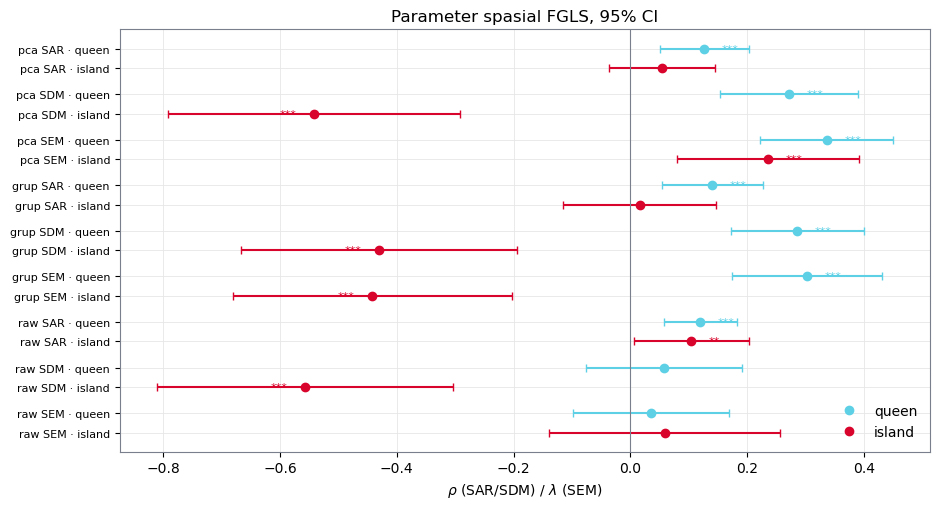

In [ ]:
fig, ax = plt.subplots(figsize=(9.5, 5.2))
sub = fitab[fitab.model.isin(["SAR", "SDM", "SEM"])].copy()
sub["lab"] = sub.X + " · " + sub.model
order = []
for x in ["pca", "grup", "raw"]:
    for m in ["SAR", "SDM", "SEM"]:
        order.append(f"{x} · {m}")
ytick, ylabels = [], []
yy = 0
for lab in order:
    chunk = sub[sub.lab == lab]
    for _, r in chunk.iterrows():
        col = W_COLOR[r.W]
        ax.errorbar(r.rho, yy, xerr=1.96 * r.se_rho if r.se_rho == r.se_rho else 0,
                    fmt="o", color=col, ecolor=col, capsize=3, ms=6)
        ax.text(r.rho + (0.03 if r.rho >= 0 else -0.03), yy, r.star_rho,
                va="center", ha="left" if r.rho >= 0 else "right", color=col, fontsize=8)
        ytick.append(yy)
        ylabels.append(f"{r.X} {r.model} · {r.W}")
        yy -= 1
    yy -= 0.35
ax.axvline(0, color=GRAY, lw=0.8)
ax.set_yticks(ytick)
ax.set_yticklabels(ylabels, fontsize=8)
ax.set_xlabel(r"$\rho$ (SAR/SDM) / $\lambda$ (SEM)")
ax.set_title("Parameter spasial FGLS, 95% CI")
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([0], [0], marker="o", color=W_COLOR[w], ls="", label=w)
                   for w in ("queen", "island")], frameon=False, loc="lower right")
fig.tight_layout()
save(fig, "eda3_rho_forest.png")
plt.show()


## Koefisien pilar (PCA dan rata-z)

--> β per +1 simpangan baku. Kiri: FGLS non-spasial.


wrote 01 Data/TFP/output/eda/eda3_coef_pilar.png


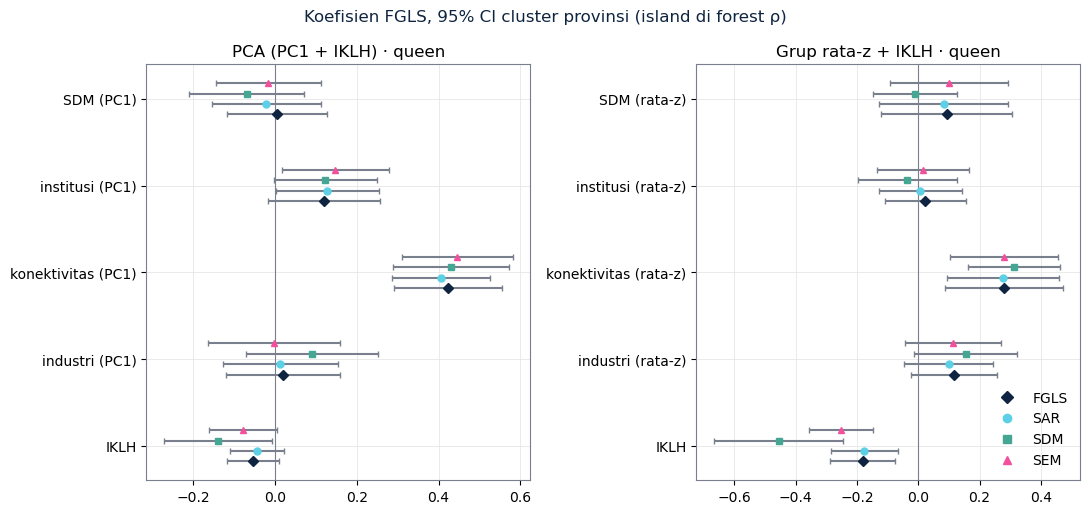

In [ ]:
def coef_panel(ax, sl, title):
    sl = sl[sl["var"] != "const"].copy()
    sl = sl[~sl["var"].str.startswith("W_")]
    sl = sl[~sl["var"].isin(["rho", "lam"])]
    sl = sl[sl.W.isin(["none", "queen"])]
    specs = [
        ("FGLS", "none", "D", NAVY),
        ("SAR", "queen", "o", CYAN),
        ("SDM", "queen", "s", TEAL),
        ("SEM", "queen", "^", PINK),
    ]
    seen, variables = [], []
    for v in sl["var"]:
        if v not in seen:
            seen.append(v)
            variables.append(v)
    ypos, ylabels = [], []
    yy = 0
    dx = {"FGLS": -0.18, "SAR": -0.06, "SDM": 0.06, "SEM": 0.18}
    for v in variables:
        ylabels.append(LAB.get(v, v))
        ypos.append(yy)
        for m, w, mk, col in specs:
            row = sl[(sl["var"] == v) & (sl.model == m) & (sl.W == w)]
            if row.empty:
                continue
            r = row.iloc[0]
            ax.errorbar(r.b, yy + dx[m], xerr=1.96 * r.se if r.se == r.se else 0,
                        fmt=mk, ms=5, color=col, ecolor=GRAY, capsize=2)
        yy -= 1
    ax.axvline(0, color=GRAY, lw=0.8)
    ax.set_yticks(ypos)
    ax.set_yticklabels(ylabels)
    ax.set_title(title)

fig, axes = plt.subplots(1, 2, figsize=(11, 5.2), sharex=False)
sl_pca = coef[(coef.X == "pca") & (coef.model.isin(["FGLS", "SAR", "SDM", "SEM"]))]
sl_g = coef[(coef.X == "grup") & (coef.model.isin(["FGLS", "SAR", "SDM", "SEM"]))]
coef_panel(axes[0], sl_pca, "PCA (PC1 + IKLH) · queen")
coef_panel(axes[1], sl_g, "Grup rata-z + IKLH · queen")
from matplotlib.lines import Line2D
axes[1].legend(handles=[
    Line2D([0], [0], marker="D", color=NAVY, ls="", label="FGLS"),
    Line2D([0], [0], marker="o", color=CYAN, ls="", label="SAR"),
    Line2D([0], [0], marker="s", color=TEAL, ls="", label="SDM"),
    Line2D([0], [0], marker="^", color=PINK, ls="", label="SEM"),
], frameon=False, loc="lower right")
fig.suptitle("Koefisien FGLS, selang 95 persen", color=NAVY)
fig.tight_layout()
save(fig, "eda3_coef_pilar.png")
plt.show()


## Penyusun mentah

--> Satu variabel, satu β pada z. FGLS.


wrote 01 Data/TFP/output/eda/eda3_coef_raw_queen.png


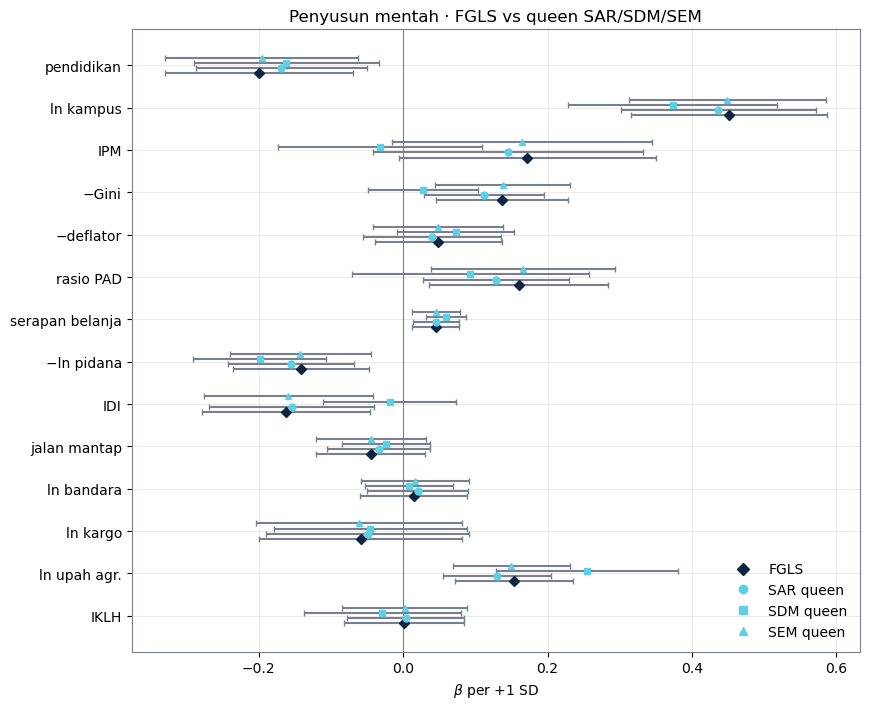

In [ ]:
fig, ax = plt.subplots(figsize=(8.8, 7.2))
sl = coef[(coef.X == "raw") & (coef.W.isin(["none", "queen"])) &
          (coef.model.isin(["FGLS", "SAR", "SDM", "SEM"]))].copy()
sl = sl[~sl["var"].str.startswith("W_") & ~sl["var"].isin(["const", "rho", "lam"])]
order = list(RAW)
yy = 0
ytick, ylabels = [], []
for v in order:
    ytick.append(yy); ylabels.append(LAB.get(v, v))
    for m, w, mk, dx in [
        ("FGLS", "none", "D", -0.18),
        ("SAR", "queen", "o", -0.06),
        ("SDM", "queen", "s", 0.06),
        ("SEM", "queen", "^", 0.18),
    ]:
        row = sl[(sl["var"] == v) & (sl.model == m)]
        if row.empty:
            continue
        r = row.iloc[0]
        ax.errorbar(r.b, yy + dx, xerr=1.96 * r.se if r.se == r.se else 0,
                    fmt=mk, ms=5, color=NAVY if m == "FGLS" else CYAN,
                    ecolor=GRAY, capsize=2)
    yy -= 1
ax.axvline(0, color=GRAY, lw=0.8)
ax.set_yticks(ytick)
ax.set_yticklabels(ylabels)
ax.set_xlabel(r"$\beta$ per +1 SD")
ax.set_title("Penyusun mentah: FGLS, queen SAR, SDM, SEM")
from matplotlib.lines import Line2D
ax.legend(handles=[
    Line2D([0], [0], marker="D", color=NAVY, ls="", label="FGLS"),
    Line2D([0], [0], marker="o", color=CYAN, ls="", label="SAR queen"),
    Line2D([0], [0], marker="s", color=CYAN, ls="", label="SDM queen"),
    Line2D([0], [0], marker="^", color=CYAN, ls="", label="SEM queen"),
], frameon=False, loc="lower right")
fig.tight_layout()
save(fig, "eda3_coef_raw_queen.png")
plt.show()


## Efek langsung dan tidak langsung

--> (I − ρW)⁻¹ (βI + θW). Dihitung pada queen dan pada W pulau.


wrote 01 Data/TFP/output/eda/eda3_effects_pilar.png


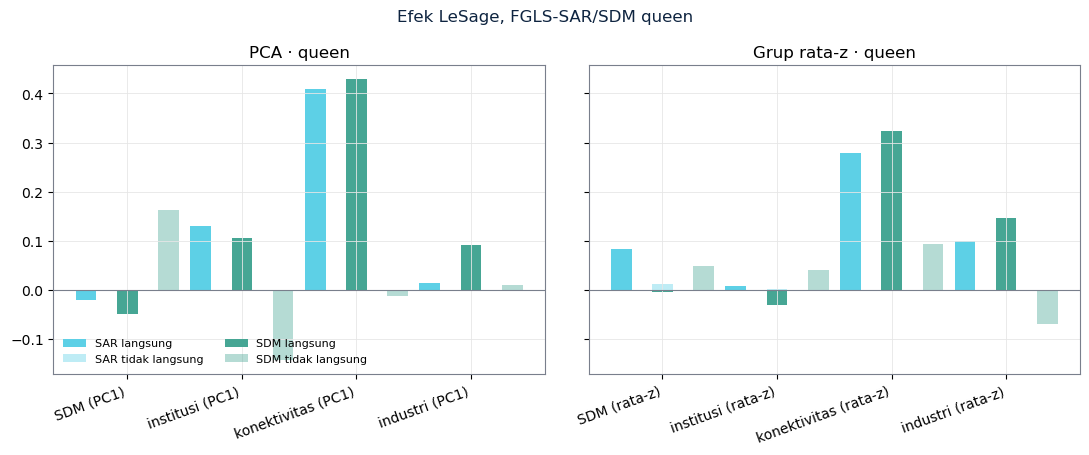

,X,W,model,var,direct,indirect,total
0,pca,queen,SAR,idx_hr,-0.020687,-0.002815,-0.023503
1,pca,queen,SAR,idx_inst,0.129553,0.017632,0.147185
2,pca,queen,SAR,idx_conn,0.409133,0.055682,0.464814
3,pca,queen,SAR,idx_ind,0.013257,0.001804,0.015061
4,pca,queen,SDM,idx_hr,-0.049603,0.162802,0.113198
5,pca,queen,SDM,idx_inst,0.106219,-0.143042,-0.036823
6,pca,queen,SDM,idx_conn,0.428544,-0.012176,0.416369
7,pca,queen,SDM,idx_ind,0.092338,0.010598,0.102936
8,pca,island,SAR,idx_hr,-0.010348,-0.000586,-0.010934
9,pca,island,SAR,idx_inst,0.125599,0.007118,0.132717


In [ ]:
if len(eff):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True)
    for ax, bname, title in zip(axes, ["pca", "grup"], ["PCA", "Grup rata-z"]):
        sl = eff[(eff.X == bname) & (eff.W == "queen")]
        xs = list(PILLARS[bname])
        x = np.arange(len(xs))
        w = 0.18
        for j, (model, col) in enumerate([("SAR", CYAN), ("SDM", TEAL)]):
            chunk = sl[sl.model == model].set_index("var").reindex(xs)
            ax.bar(x + (j - 0.5) * 2 * w - w, chunk.direct, width=w, color=col, label=f"{model} langsung")
            ax.bar(x + (j - 0.5) * 2 * w + w, chunk.indirect, width=w, color=col, alpha=0.4, label=f"{model} tidak langsung")
        ax.axhline(0, color=GRAY, lw=0.8)
        ax.set_xticks(x)
        ax.set_xticklabels([LAB.get(v, v) for v in xs], rotation=20, ha="right")
        ax.set_title(f"{title} · queen")
        if bname == "pca":
            ax.legend(frameon=False, fontsize=8, ncol=2)
    fig.suptitle("Efek LeSage, FGLS-SAR/SDM queen", color=NAVY)
    fig.tight_layout()
    save(fig, "eda3_effects_pilar.png")
    plt.show()
eff.head(12)


## Moran sisa FGLS

--> Rata-rata provinsi, N = 34.


wrote 01 Data/TFP/output/eda/eda3_moran_resid.png


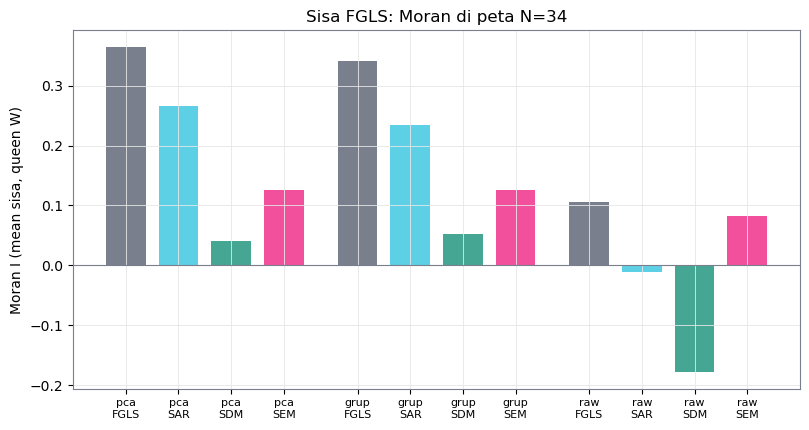

In [ ]:
moran_rows = []
g = wmeta["gdf"]
for (bname, wname, kind), fit in fits.items():
    e = fit["e"]
    em = e.reshape(T, n).mean(axis=0)
    for wn, WW in Wmap.items():
        moran_rows.append({
            "X": bname, "W_model": wname, "model": kind, "W_moran": wn,
            "I_mean": moran(em, WW),
        })
mdf = pd.DataFrame(moran_rows)
mdf.to_csv(OUT / "eda3_moran_resid.csv", index=False)

fig, ax = plt.subplots(figsize=(8.2, 4.4))
show = mdf[(mdf.W_moran == "queen") & (mdf.model.isin(["FGLS", "SAR", "SDM", "SEM"]))]
xpos, labs = [], []
x = 0
for bname in ["pca", "grup", "raw"]:
    for kind, col in [("FGLS", GRAY), ("SAR", CYAN), ("SDM", TEAL), ("SEM", PINK)]:
        chunk = show[(show.X == bname) & (show.model == kind)]
        # FGLS stored as W_model=none; spatial as queen/island — plot queen-estimated + FGLS
        if kind == "FGLS":
            chunk = chunk[chunk.W_model == "none"]
        else:
            chunk = chunk[chunk.W_model == "queen"]
        if chunk.empty:
            continue
        ax.bar(x, chunk.I_mean.iloc[0], color=col, width=0.75)
        xpos.append(x); labs.append(f"{bname}\n{kind}")
        x += 1
    x += 0.4
ax.axhline(0, color=GRAY, lw=0.8)
ax.set_xticks(xpos)
ax.set_xticklabels(labs, fontsize=8)
ax.set_ylabel("Moran I (mean sisa, queen W)")
ax.set_title("Moran sisa FGLS, N = 34")
fig.tight_layout()
save(fig, "eda3_moran_resid.png")
plt.show()


wrote 01 Data/TFP/output/eda/eda3_map_resid.png


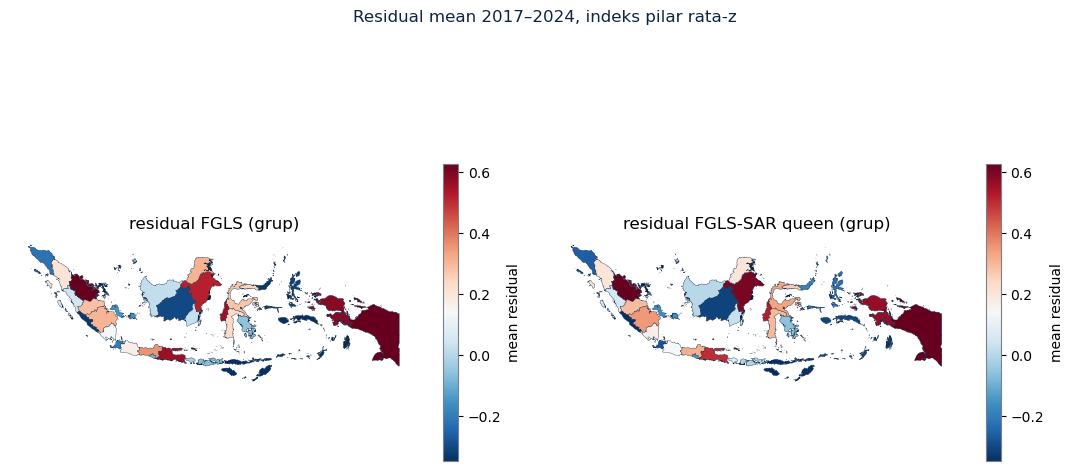

In [ ]:
# peta sisa: FGLS vs queen SAR, blok grup (pilar rata-z)
import geopandas as gpd
g = wmeta["gdf"].copy()
g = g.to_crs(4326)
e_fgls = fits[("grup", "none", "FGLS")]["e"].reshape(T, n).mean(0)
e_sar = fits[("grup", "queen", "SAR")]["e"].reshape(T, n).mean(0)
g = g.reset_index()
g["e_fgls"] = e_fgls
g["e_sar"] = e_sar
g["Pulau"] = g.Code_Prov.map(pulau)

fig, axes = plt.subplots(1, 2, figsize=(11, 6))
vmin = np.nanpercentile(np.r_[e_fgls, e_sar], 5)
vmax = np.nanpercentile(np.r_[e_fgls, e_sar], 95)
for ax, col, title in zip(axes, ["e_fgls", "e_sar"], ["residual FGLS (grup)", "residual FGLS-SAR queen (grup)"]):
    g.plot(column=col, ax=ax, cmap="RdBu_r", vmin=vmin, vmax=vmax,
           edgecolor=NAVY, linewidth=0.25, legend=True,
           legend_kwds={"shrink": 0.55, "label": "sisa rata-rata"})
    ax.set_axis_off()
    ax.set_title(title)
fig.suptitle("Sisa rata-rata 2017–2024, indeks pilar rata-z", color=NAVY)
fig.tight_layout()
save(fig, "eda3_map_resid.png")
plt.show()


## AIC / LR kasar


pca  queen   LR SAR= 10.47 p=0.001  LR SEM= 28.05  ΔAIC SDM-SAR=  -9.6
pca  island  LR SAR=  1.37 p=0.242  LR SEM=  7.36  ΔAIC SDM-SAR=  12.6
grup queen   LR SAR=  9.79 p=0.002  LR SEM= 19.47  ΔAIC SDM-SAR= -57.4
grup island  LR SAR=  0.06 p=0.811  LR SEM= 13.49  ΔAIC SDM-SAR= -48.4
raw  queen   LR SAR= 13.41 p=0.000  LR SEM=  0.27  ΔAIC SDM-SAR= -80.1
raw  island  LR SAR=  4.25 p=0.039  LR SEM=  0.33  ΔAIC SDM-SAR=-178.8
wrote 01 Data/TFP/output/eda/eda3_aic.png


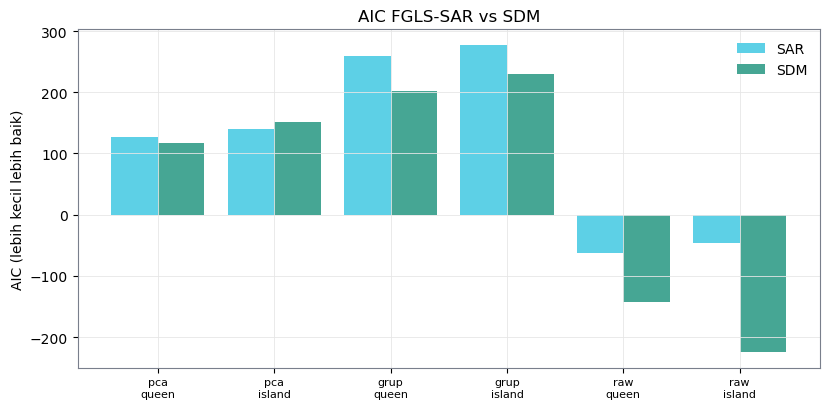

,X,W,LR_SAR_vs_FGLS,p_SAR,LR_SEM_vs_FGLS,p_SEM,AIC_FGLS,AIC_SLX,AIC_SAR,AIC_SDM,AIC_SEM,dAIC_SDM_SAR
0,pca,queen,10.467407,0.001215,28.051631,1.181215e-07,147.051450,153.198259,127.127246,117.503076,149.302060,-9.624170
1,pca,island,1.369553,0.241889,7.362510,6.659775e-03,147.051450,260.330770,139.403818,152.046676,133.318894,12.642858
2,grup,queen,9.787398,0.001757,19.469678,1.022094e-05,265.967243,207.652607,260.096221,202.719742,258.061272,-57.376479
3,grup,island,0.057084,0.811166,13.485400,2.404269e-04,265.967243,219.815697,277.764089,229.356409,234.513962,-48.407680
4,raw,queen,13.407282,0.000251,0.265195,6.065733e-01,-42.982029,-140.768950,-63.138945,-143.271850,-42.701868,-80.132906
5,raw,island,4.245515,0.039354,0.333229,5.637640e-01,-42.982029,-218.299497,-46.103196,-224.897872,-44.174593,-178.794676


In [ ]:
from eda3_spatial_fgls import wls, apply_W, stack_WX, logdet_I_rhoW, _ll

def ll_at(y, X, W, T, inv, kind, rho):
    if kind == "SEM":
        Ay = y - rho * apply_W(y, W, T)
        AX = X - rho * stack_WX(X, W, T)
        b = wls(Ay, AX, inv)
        e = Ay - AX @ b
        ld = logdet_I_rhoW(rho, W)
    elif kind in ("SAR", "SDM"):
        Ay = y - rho * apply_W(y, W, T)
        b = wls(Ay, X, inv)
        e = Ay - X @ b
        ld = logdet_I_rhoW(rho, W)
    else:
        b = wls(y, X, inv)
        e = y - X @ b
        ld = 0.0
    return _ll(e, inv, T, ld)

lr_rows = []
for bname, cols in BLOCKS.items():
    X0 = np.column_stack([np.ones(len(d)), d[cols].to_numpy()])
    names0 = ["const"] + list(cols)
    for wname, W in Wmap.items():
        sar = fits[(bname, wname, "SAR")]
        sdm = fits[(bname, wname, "SDM")]
        sem = fits[(bname, wname, "SEM")]
        fgl = fits[(bname, "none", "FGLS")]
        # SAR vs FGLS at SAR weights, rho=0
        ll_r = ll_at(y, sar["X"], W, T, sar["inv"], "SAR", 0.0)
        lr_sar = 2 * (sar["ll"] - ll_r)
        # SDM vs SAR at SDM weights: compare SDM vs SAR-like (no WX) is not same X
        # use AIC difference instead for SDM vs SAR
        lr_sem = 2 * (sem["ll"] - ll_at(y, sem["X"], W, T, sem["inv"], "SEM", 0.0))
        lr_rows.append({
            "X": bname, "W": wname,
            "LR_SAR_vs_FGLS": lr_sar, "p_SAR": float(chi2.sf(max(lr_sar, 0), 1)),
            "LR_SEM_vs_FGLS": lr_sem, "p_SEM": float(chi2.sf(max(lr_sem, 0), 1)),
            "AIC_FGLS": fgl["aic"], "AIC_SLX": fits[(bname, wname, "SLX")]["aic"],
            "AIC_SAR": sar["aic"], "AIC_SDM": sdm["aic"], "AIC_SEM": sem["aic"],
            "dAIC_SDM_SAR": sdm["aic"] - sar["aic"],
        })
        print(f"{bname:4s} {wname:6s}  LR SAR={lr_sar:6.2f} p={chi2.sf(max(lr_sar,0),1):.3f}  "
              f"LR SEM={lr_sem:6.2f}  ΔAIC SDM-SAR={sdm['aic']-sar['aic']:6.1f}")

lr = pd.DataFrame(lr_rows)
lr.to_csv(OUT / "eda3_lr.csv", index=False)

fig, ax = plt.subplots(figsize=(8.4, 4.2))
x = np.arange(len(lr))
ax.bar(x - 0.2, lr.AIC_SAR, 0.4, color=CYAN, label="SAR")
ax.bar(x + 0.2, lr.AIC_SDM, 0.4, color=TEAL, label="SDM")
ax.set_xticks(x)
ax.set_xticklabels([f"{r.X}\n{r.W}" for _, r in lr.iterrows()], fontsize=8)
ax.set_ylabel("AIC")
ax.set_title("AIC, FGLS-SAR dan SDM")
ax.legend(frameon=False)
fig.tight_layout()
save(fig, "eda3_aic.png")
plt.show()
lr
